In [2]:
import numpy as np 
from langchain_ollama import OllamaEmbeddings

In [3]:
def dot_loop(a,b):
    total=0.0
    for x,y in zip(a,b):
        total+= x*y
    return total

In [4]:
def cosine_loop(a,b):
    return dot_loop(a,b)/((dot_loop(a,a)**0.5)*(dot_loop(b,b)**0.5))

In [5]:
a,b,c,d = [3,4],[4,3],[-4,3],[6,8] 
print(cosine_loop(a,b), cosine_loop(a,c),cosine_loop(a,d))

0.96 0.0 1.0


In [6]:
def cosine(a,b):
    a,b = np.array(a), np.array(b)
    return np.dot(a,b)/(np.linalg.norm(a)*np.linalg.norm(b))

print(cosine(a,b), cosine(a,c), cosine(a,d))

0.96 0.0 1.0


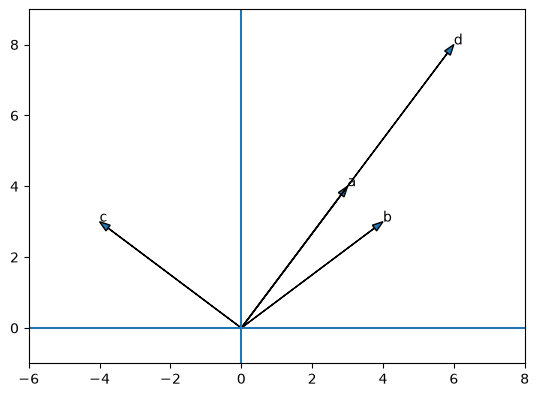

In [7]:
import matplotlib.pyplot as plt
for v, name in [(a, "a"), (b, "b"), (c, "c"), (d, "d")]:
    plt.arrow(0, 0, v[0], v[1], head_width=0.2, length_includes_head=True)
    plt.text(v[0], v[1], name)
plt.xlim(-6, 8); plt.ylim(-1, 9); plt.axhline(0); plt.axvline(0); plt.gca().set_aspect("equal")
plt.show()

In [9]:
emb = OllamaEmbeddings(model = "nomic-embed-text")
sentences = [
    "How do I control weeds in sesame?",
    "Which herbicide works against weeds in a sesame field?",
    "Sesame leaf spot disease treatment",
    "Best time to sow wheat in Punjab",
    "The India versus Australia cricket match starts at 2 pm",
    "How to fix a segmentation fault in C++",
]
vecs = emb.embed_documents(sentences)

E= np.array(vecs)

print(E.shape)



(6, 768)


In [10]:
En= E/ np.linalg.norm (E, axis=1 , keepdims= True)
S = En @ En.T
print(np.round(S, 2))

[[1.   0.87 0.72 0.5  0.36 0.39]
 [0.87 1.   0.72 0.52 0.39 0.37]
 [0.72 0.72 1.   0.47 0.34 0.45]
 [0.5  0.52 0.47 1.   0.5  0.35]
 [0.36 0.39 0.34 0.5  1.   0.36]
 [0.39 0.37 0.45 0.35 0.36 1.  ]]


In [11]:
order = np.argsort(-S[0])
for i in order:
    print(round(S[0, i], 3), sentences[i])

1.0 How do I control weeds in sesame?
0.867 Which herbicide works against weeds in a sesame field?
0.717 Sesame leaf spot disease treatment
0.502 Best time to sow wheat in Punjab
0.395 How to fix a segmentation fault in C++
0.358 The India versus Australia cricket match starts at 2 pm


In [12]:
q = np.array(emb.embed_query(
    "What is the way to get rid of unwanted plants growing between my til crop rows?"))
qn = q / np.linalg.norm(q)
scores = En @ qn
for i in np.argsort(-scores):
    print(round(scores[i], 3), sentences[i])

0.636 How do I control weeds in sesame?
0.598 Which herbicide works against weeds in a sesame field?
0.542 Sesame leaf spot disease treatment
0.515 Best time to sow wheat in Punjab
0.447 How to fix a segmentation fault in C++
0.309 The India versus Australia cricket match starts at 2 pm


In [13]:
docs_p = ["search_document: " + s for s in sentences]
Ep = np.array(emb.embed_documents(docs_p))
Epn = Ep / np.linalg.norm(Ep, axis=1, keepdims=True)

qtext = "What is the way to get rid of unwanted plants growing between my til crop rows?"
qp = np.array(emb.embed_query("search_query: " + qtext))
qpn = qp / np.linalg.norm(qp)
scores_p = Epn @ qpn

for i in np.argsort(-scores_p):
    print(round(scores_p[i], 3), sentences[i])

rel, irr = [0, 1], [2, 3, 4, 5]
def margin(sc):
    return min(sc[rel]) - max(sc[irr])

print("margin without prefix:", round(margin(scores), 3))
print("margin with prefix:   ", round(margin(scores_p), 3))

0.552 Which herbicide works against weeds in a sesame field?
0.536 How do I control weeds in sesame?
0.518 Best time to sow wheat in Punjab
0.485 Sesame leaf spot disease treatment
0.415 How to fix a segmentation fault in C++
0.341 The India versus Australia cricket match starts at 2 pm
margin without prefix: 0.056
margin with prefix:    0.018


In [16]:
docs_p = ["search_document: " + s for s in sentences]
Ep = np.array(emb.embed_documents(docs_p))
Epn = Ep / np.linalg.norm(Ep, axis=1, keepdims=True)

qtext = "तिल की फसल में खरपतवार का नियंत्रण कैसे करें?"
qp = np.array(emb.embed_query("search_query: " + qtext))
qpn = qp / np.linalg.norm(qp)
scores_p = Epn @ qpn

for i in np.argsort(-scores_p):
    print(round(scores_p[i], 3), sentences[i])

rel, irr = [0, 1], [2, 3, 4, 5]
def margin(sc):
    return min(sc[rel]) - max(sc[irr])

print("margin without prefix:", round(margin(scores), 3))
print("margin with prefix:   ", round(margin(scores_p), 3))

0.527 The India versus Australia cricket match starts at 2 pm
0.454 Best time to sow wheat in Punjab
0.429 Sesame leaf spot disease treatment
0.402 How to fix a segmentation fault in C++
0.38 Which herbicide works against weeds in a sesame field?
0.348 How do I control weeds in sesame?
margin without prefix: 0.056
margin with prefix:    -0.18


In [17]:
emb_m3 = OllamaEmbeddings(model="bge-m3")
E3 = np.array(emb_m3.embed_documents(sentences))
E3n = E3 / np.linalg.norm(E3, axis=1, keepdims=True)
print(E3.shape)          # read the dimension from here, don't assume

def rank(model, En_matrix, query):
    q = np.array(model.embed_query(query))
    q = q / np.linalg.norm(q)
    sc = En_matrix @ q
    for i in np.argsort(-sc):
        print(round(sc[i], 3), sentences[i])
    return sc

hi_q = "तिल की फसल में खरपतवार का नियंत्रण कैसे करें?"
sc_nomic = rank(emb, En, hi_q)
sc_m3 = rank(emb_m3, E3n, hi_q)
print(margin(sc_nomic), margin(sc_m3))

(6, 1024)
0.524 The India versus Australia cricket match starts at 2 pm
0.452 Best time to sow wheat in Punjab
0.426 Sesame leaf spot disease treatment
0.4 How to fix a segmentation fault in C++
0.382 Which herbicide works against weeds in a sesame field?
0.351 How do I control weeds in sesame?
0.559 How do I control weeds in sesame?
0.496 Which herbicide works against weeds in a sesame field?
0.43 Best time to sow wheat in Punjab
0.407 Sesame leaf spot disease treatment
0.397 How to fix a segmentation fault in C++
0.286 The India versus Australia cricket match starts at 2 pm
-0.1733774543855 0.0659473365059004
